# 🚀 PropulPy Quickstart: Diseño Inverso de Tobera, Balística Interna y Acoplamiento con RocketPy

Bienvenido al tutorial interactivo principal de **PropulPy**. En este notebook recorreremos paso a paso el flujo de trabajo de ingeniería para diseñar, auditar y simular un motor cohete de propelente sólido (basado en el motor **UltraLuminics 2× BATES KNSB** lanzado a la altitud de Bogotá, $2600\text{ m}$ MSNM).

### ¿Qué aprenderás en este notebook?
1. **Arquitectura general de `PropulPy`**: Cómo se conectan la termoquímica, la atmósfera de lanzamiento, el diseño inverso y la balística interna.
2. **Diseño inverso de tobera (`dimension_nozzle`)**: Cómo pasar intuitivamente desde los datos de la garganta ($D_t$), la presión de cámara ($P_c$) y la **presión estática de salida deseada ($P_e$)** hacia todas las cotas de mecanizado ($D_e, L_{\text{conv}}, L_t, L_{\text{div}}$) y el desempeño supersónico ($M_e, C_f, F$).
3. **Regímenes de expansión y criterio de Summerfield**: Visualización de sub-expansión, adaptación óptima ($P_e = P_a$) y separación de flujo por sobre-expansión ($P_e < 0.35\,P_a$).
4. **Geometrías de grano 1D y 2D EDT (`BATES`, `Finocyl`, `Star`, `EndBurner`)**: Mapas de regresión por Transformada de Distancia Euclidiana.
5. **Simulación cuasi-estacionaria con descarga (*blowdown*) y exportación a `RocketPy` / `openMotor` (`.ric` y `.eng`)**.

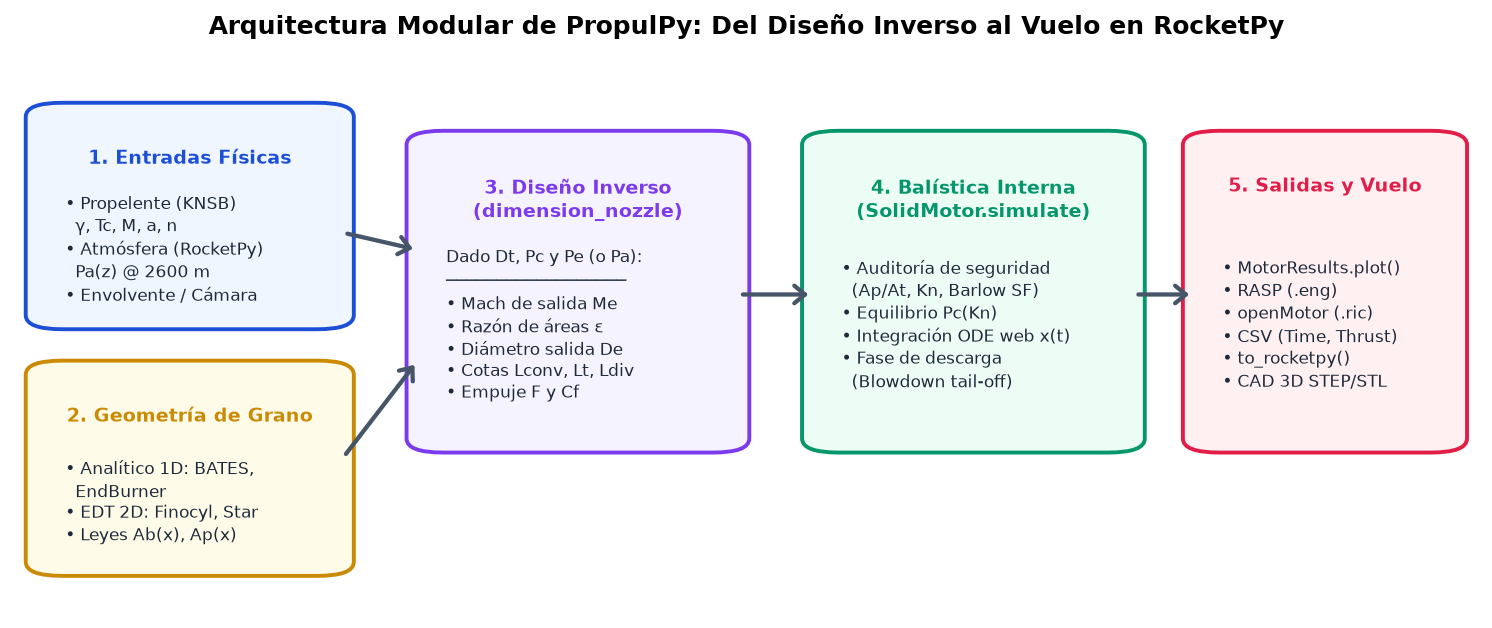

In [1]:
from pathlib import Path

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np

# Directorio para almacenar las figuras ilustrativas generadas por código
fig_dir = Path("examples/figures") if Path("examples").exists() else Path("figures")
fig_dir.mkdir(parents=True, exist_ok=True)


def plot_propulpy_architecture(save_path: Path | None = None):
    """Genera un diagrama visual de bloques de la arquitectura de PropulPy."""
    fig, ax = plt.subplots(figsize=(13.5, 5.2), dpi=140)
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.axis("off")
    ax.set_title(
        "Arquitectura Modular de PropulPy: Del Diseño Inverso al Vuelo en RocketPy",
        fontsize=13,
        fontweight="bold",
        pad=10,
    )

    blocks = [
        (
            2,
            52,
            20,
            38,
            "#eff6ff",
            "#1d4ed8",
            "1. Entradas Físicas",
            "• Propelente (KNSB)\n  γ, Tc, M, a, n\n• Atmósfera (RocketPy)\n  Pa(z) @ 2600 m\n• Envolvente / Cámara",
        ),
        (
            2,
            8,
            20,
            36,
            "#fefce8",
            "#ca8a04",
            "2. Geometría de Grano",
            "• Analítico 1D: BATES,\n  EndBurner\n• EDT 2D: Finocyl, Star\n• Leyes Ab(x), Ap(x)",
        ),
        (
            28,
            30,
            21,
            55,
            "#f5f3ff",
            "#7c3aed",
            "3. Diseño Inverso\n(dimension_nozzle)",
            "Dado Dt, Pc y Pe (o Pa):\n──────────────────\n• Mach de salida Me\n• Razón de áreas ε\n• Diámetro salida De\n• Cotas Lconv, Lt, Ldiv\n• Empuje F y Cf",
        ),
        (
            55,
            30,
            21,
            55,
            "#ecfdf5",
            "#059669",
            "4. Balística Interna\n(SolidMotor.simulate)",
            "• Auditoría de seguridad\n  (Ap/At, Kn, Barlow SF)\n• Equilibrio Pc(Kn)\n• Integración ODE web x(t)\n• Fase de descarga\n  (Blowdown tail-off)",
        ),
        (
            81,
            30,
            17,
            55,
            "#fff1f2",
            "#e11d48",
            "5. Salidas y Vuelo",
            "• MotorResults.plot()\n• RASP (.eng)\n• openMotor (.ric)\n• CSV (Time, Thrust)\n• to_rocketpy()\n• CAD 3D STEP/STL",
        ),
    ]

    for x, y, w, h, fc, ec, title, body in blocks:
        patch = mpatches.FancyBboxPatch(
            (x, y),
            w,
            h,
            boxstyle="round,pad=1.2,rounding_size=2.5",
            fc=fc,
            ec=ec,
            lw=2,
        )
        ax.add_patch(patch)
        ax.text(
            x + w / 2,
            y + h - 7,
            title,
            ha="center",
            va="top",
            fontsize=10,
            fontweight="bold",
            color=ec,
        )
        ax.text(
            x + 1.5,
            y + (h - 12) / 2,
            body,
            ha="left",
            va="center",
            fontsize=8.6,
            color="#1e293b",
            linespacing=1.35,
        )

    arrow_kw = {
        "arrowstyle": "->,head_width=0.45,head_length=0.55",
        "lw": 2.2,
        "color": "#475569",
    }
    ax.annotate("", xy=(27.5, 65), xytext=(22.5, 68), arrowprops=arrow_kw)
    ax.annotate("", xy=(27.5, 45), xytext=(22.5, 28), arrowprops=arrow_kw)
    ax.annotate("", xy=(54.5, 57), xytext=(49.5, 57), arrowprops=arrow_kw)
    ax.annotate("", xy=(80.5, 57), xytext=(76.5, 57), arrowprops=arrow_kw)

    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


plot_propulpy_architecture(fig_dir / "01_propulpy_architecture.png")

---
## 1. Condiciones Atmosféricas (`Environment`) y Propelente (`KNSB`)

El desempeño de una tobera supersónica depende directamente de la **presión atmosférica ambiente $P_a(z)$**. A $2600\text{ m}$ sobre el nivel del mar (Bogotá), la presión atmosférica cae de $1.013\text{ bar}$ a aproximadamente $0.737\text{ bar}$.

`PropulPy` acepta directamente un objeto `rocketpy.Environment` para extraer $P_a(z)$ automáticamente. A su vez, cargamos de la librería termoquímica el propelente **KNSB 65/35** ($65\%\text{ KNO}_3 / 35\%\text{ Sorbitol}$), cuya velocidad de quemado sigue la ley de **Saint-Robert (Vielle)** por tramos de presión:

$$r(P_c) = a \cdot P_c^n \quad [\text{m/s}]$$

In [2]:
from rocketpy import Environment

from propulpy import BATES, KNSB, Chamber, EndBurner, Finocyl, SolidMotor, Star
from propulpy.analysis.checks import print_check_report
from propulpy.design.nozzle import dimension_nozzle

# 1. Entorno de lanzamiento: Bogotá (2600 m MSNM)
env = Environment(latitude=4.60, longitude=-74.08, elevation=2600.0)
p_amb_bogota = float(env.pressure(2600.0))

# 2. Propelente KNSB (con eficiencia de velocidad característica eta_c* = 95%)
prop = KNSB(cstar_efficiency=0.95)

print(
    f"Presión atmosférica en Bogotá (2600 m): {p_amb_bogota / 1e5:.3f} bar ({p_amb_bogota:.0f} Pa)"
)
print(f"Propelente seleccionado               : {prop.name}")
print(f"  * Densidad (rho_p)                  : {prop.density:.1f} kg/m^3")
print(f"  * Razón de calores específicos (k)  : {prop.k:.4f}")
print(f"  * Temperatura de cámara (Tc)        : {prop.combustion_temperature:.1f} K")
print(f"  * Velocidad característica (c*)     : {prop.cstar:.1f} m/s")

Presión atmosférica en Bogotá (2600 m): 0.738 bar (73758 Pa)
Propelente seleccionado               : KNSB
  * Densidad (rho_p)                  : 1750.0 kg/m^3
  * Razón de calores específicos (k)  : 1.1361
  * Temperatura de cámara (Tc)        : 1520.0 K
  * Velocidad característica (c*)     : 840.9 m/s


---
## 2. Diseño Inverso de Tobera (`dimension_nozzle`): De la Garganta y Presión de Salida Requerida a las Cotas de la Tobera

Una de las funciones más potentes de `PropulPy` es `dimension_nozzle()`.

### ¿Qué problema resuelve `dimension_nozzle`?
Cuando diseñamos un motor cohete, conocemos:
1. **El diámetro de garganta $D_t$** (fijado por la relación de Klemmung $K_n = A_b / A_t$ para sostener la presión de cámara deseada).
2. **La presión nominal de cámara $P_c$** (p. ej. $40\text{ bar}$).
3. **El diámetro interno de la cámara $D_c$** (p. ej. $42\text{ mm}$).
4. **La presión estática de salida de gas que requerimos a la salida de la tobera ($P_e$)** (ya sea especificando explícitamente `target_exit_pressure=Pe`, o dejando que `PropulPy` adapte la tobera a `ambient_pressure` con un factor de seguridad `area_ratio_safety_factor=0.85`).

A partir de estos datos, `dimension_nozzle()` invierte exactamente las ecuaciones isentrópicas de flujo compresible 1D:

1. **Número de Mach de salida requerido ($M_e$)** para abatir la presión desde $P_c$ hasta $P_e$:
   $$M_e = \sqrt{\frac{2}{\gamma - 1}\left[\left(\frac{P_c}{P_e}\right)^{\frac{\gamma - 1}{\gamma}} - 1\right]}$$
2. **Razón de expansión geométrica necesaria ($\varepsilon = A_e / A_t$)** y diámetro de salida $D_e = D_t\sqrt{\varepsilon}$:
   $$\varepsilon = \frac{A_e}{A_t} = \frac{1}{M_e}\left[\frac{2}{\gamma + 1}\left(1 + \frac{\gamma - 1}{2}M_e^2\right)\right]^{\frac{\gamma + 1}{2(\gamma - 1)}}$$
3. **Longitudes axiales de los conos convergente y divergente** para los semiángulos $\beta$ y $\alpha$:
   $$L_{\text{conv}} = \frac{D_c - D_t}{2\tan\beta}, \qquad L_{\text{div}} = \frac{D_e - D_t}{2\tan\alpha}$$

Ejecutemos `dimension_nozzle()` y llamemos a su método visual `.plot()` para observar el plano técnico completo y la caída de presión del gas dentro de la tobera:

                 CONICAL NOZZLE DIMENSION REPORT
MACHINING GEOMETRY (mm):
  * Throat Diameter (Dt)     : 5.88 mm
  * Exit Diameter (De)       : 15.79 mm
  * Convergent Length (Lconv): 31.28 mm  (half-angle = 30.0°)
  * Throat Land Length (Lt)  : 1.18 mm
  * Divergent Length (Ldiv)  : 18.49 mm  (half-angle = 15.0°)
  * Total Nozzle Length      : 50.95 mm
-----------------------------------------------------------------
GAS DYNAMICS & DELIVERED PERFORMANCE:
  * Expansion Ratio (eps)    : 7.21
  * Exit Mach Number (Me)    : 2.903
  * Exit Static Pressure (Pe): 0.909 bar (90863 Pa)
  * Delivered Cf             : 1.415
  * Delivered Thrust         : 153.7 N


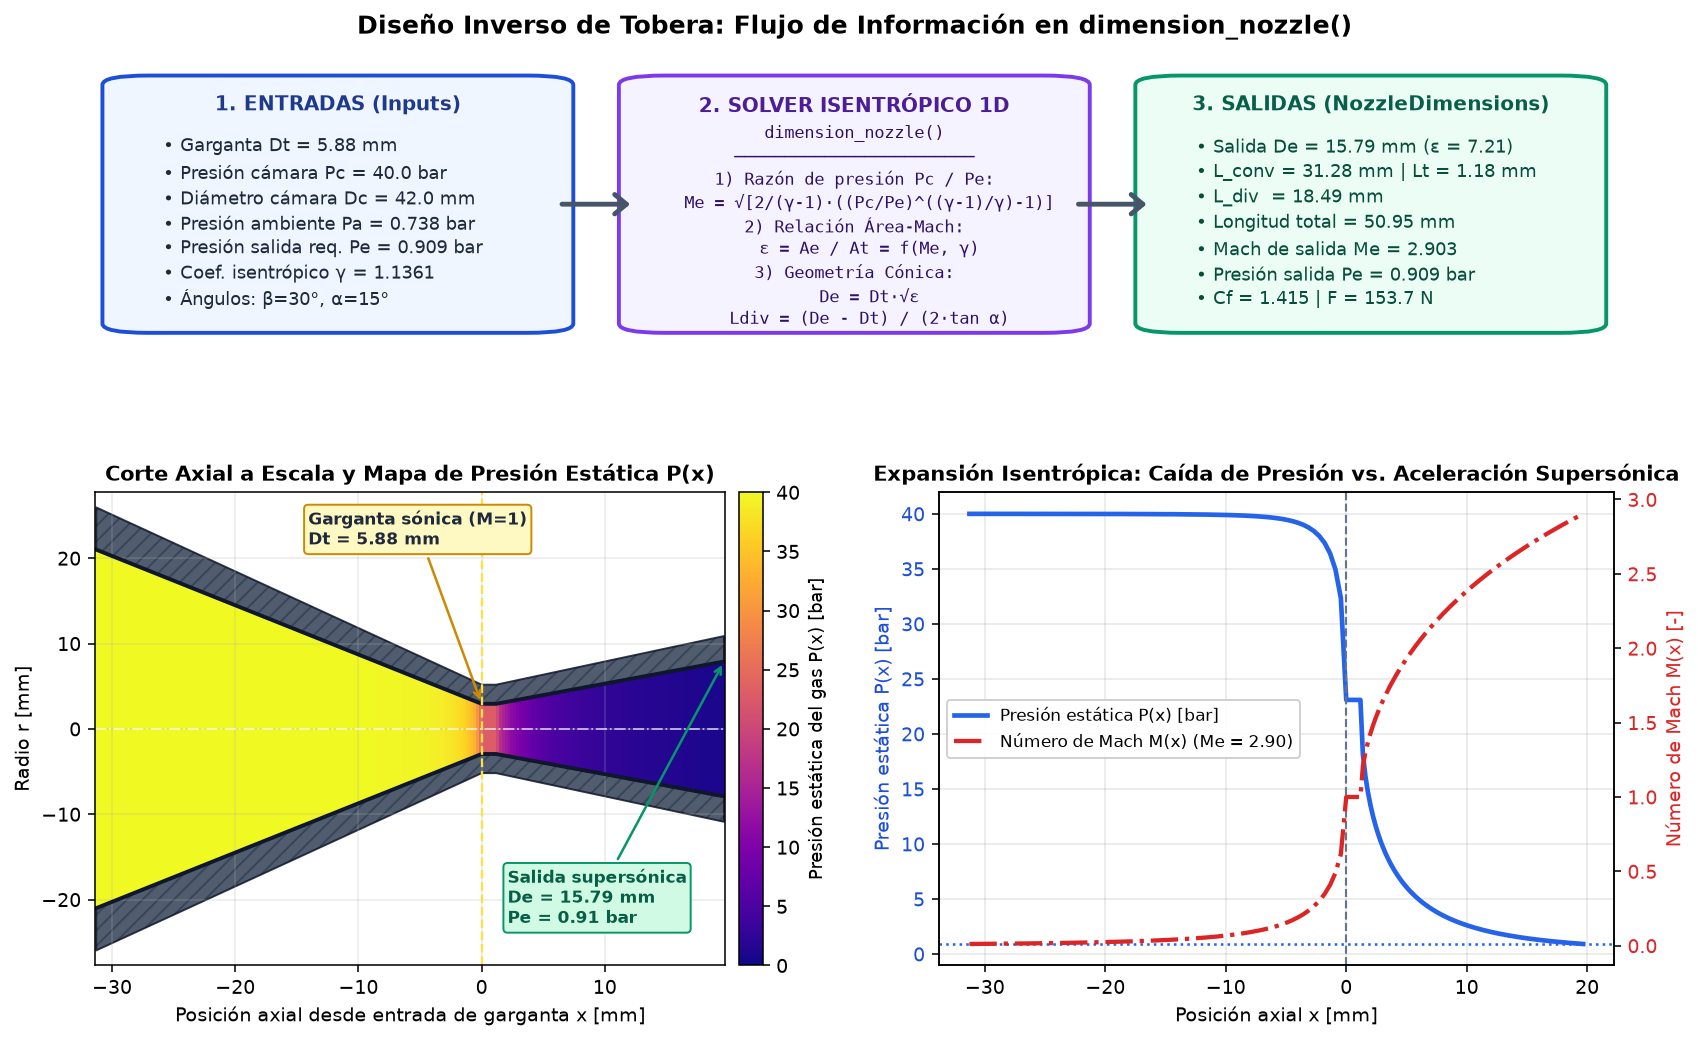

In [3]:
# Dimensionamiento inverso de la tobera para Pc = 40 bar en Bogotá
nozzle_dims = dimension_nozzle(
    throat_diameter=5.88e-3,  # Garganta Dt = 5.88 mm
    chamber_pressure=40.0e5,  # Presión de cámara Pc = 40 bar
    propellant=prop,  # Propelente KNSB (gamma = 1.1361)
    chamber_diameter=42.0e-3,  # Diámetro interno de cámara Dc = 42.0 mm
    ambient_pressure=env,  # Atmósfera a 2600 m (Pa = 0.737 bar)
    area_ratio_safety_factor=0.85,  # Margen del 85% sobre expansión óptima
    efficiency=0.90,  # Eficiencia de tobera
)

# 1. Reporte numérico detallado
nozzle_dims.report()

# 2. Imagen ilustrativa generada por código: Entrada -> Solver -> Corte 2D y Perfil P(x), M(x)
_ = nozzle_dims.plot(save_path=fig_dir / "02_dimension_nozzle_blueprint.png")

---
### 2.1 Especificando directamente un nivel exacto de presión saliente (`target_exit_pressure`) y Regímenes de Expansión

¿Qué sucede si queremos que el gas salga de la tobera exactamente a una **presión estática objetivo $P_e$** dada por nosotros (por ejemplo, $P_e = 1.0\text{ bar}$, $P_e = 0.737\text{ bar}$ o $P_e = 0.40\text{ bar}$)?

Simplemente pasamos el parámetro `target_exit_pressure` a `dimension_nozzle()`. En la siguiente celda generamos por código una **infografía comparativa** que barre distintos niveles de presión de salida $P_e$ requeridos y muestra:
- Cómo cambia el **diámetro de salida requerido $D_e$** y la **longitud divergente $L_{\text{div}}$** para alcanzar cada presión saliente $P_e$.
- Cómo responde el **coeficiente de empuje $C_f$**, alcanzando su máximo absoluto cuando la presión de salida iguala a la presión ambiente ($P_e = P_a$).
- La **zona crítica de separación de Summerfield ($P_e < 0.35\,P_a$)**, donde el gas se sobre-expande tanto que la presión atmosférica exterior empuja la capa límite hacia adentro, provocando ondas de choque oblicuas e inestabilidad lateral en la tobera.

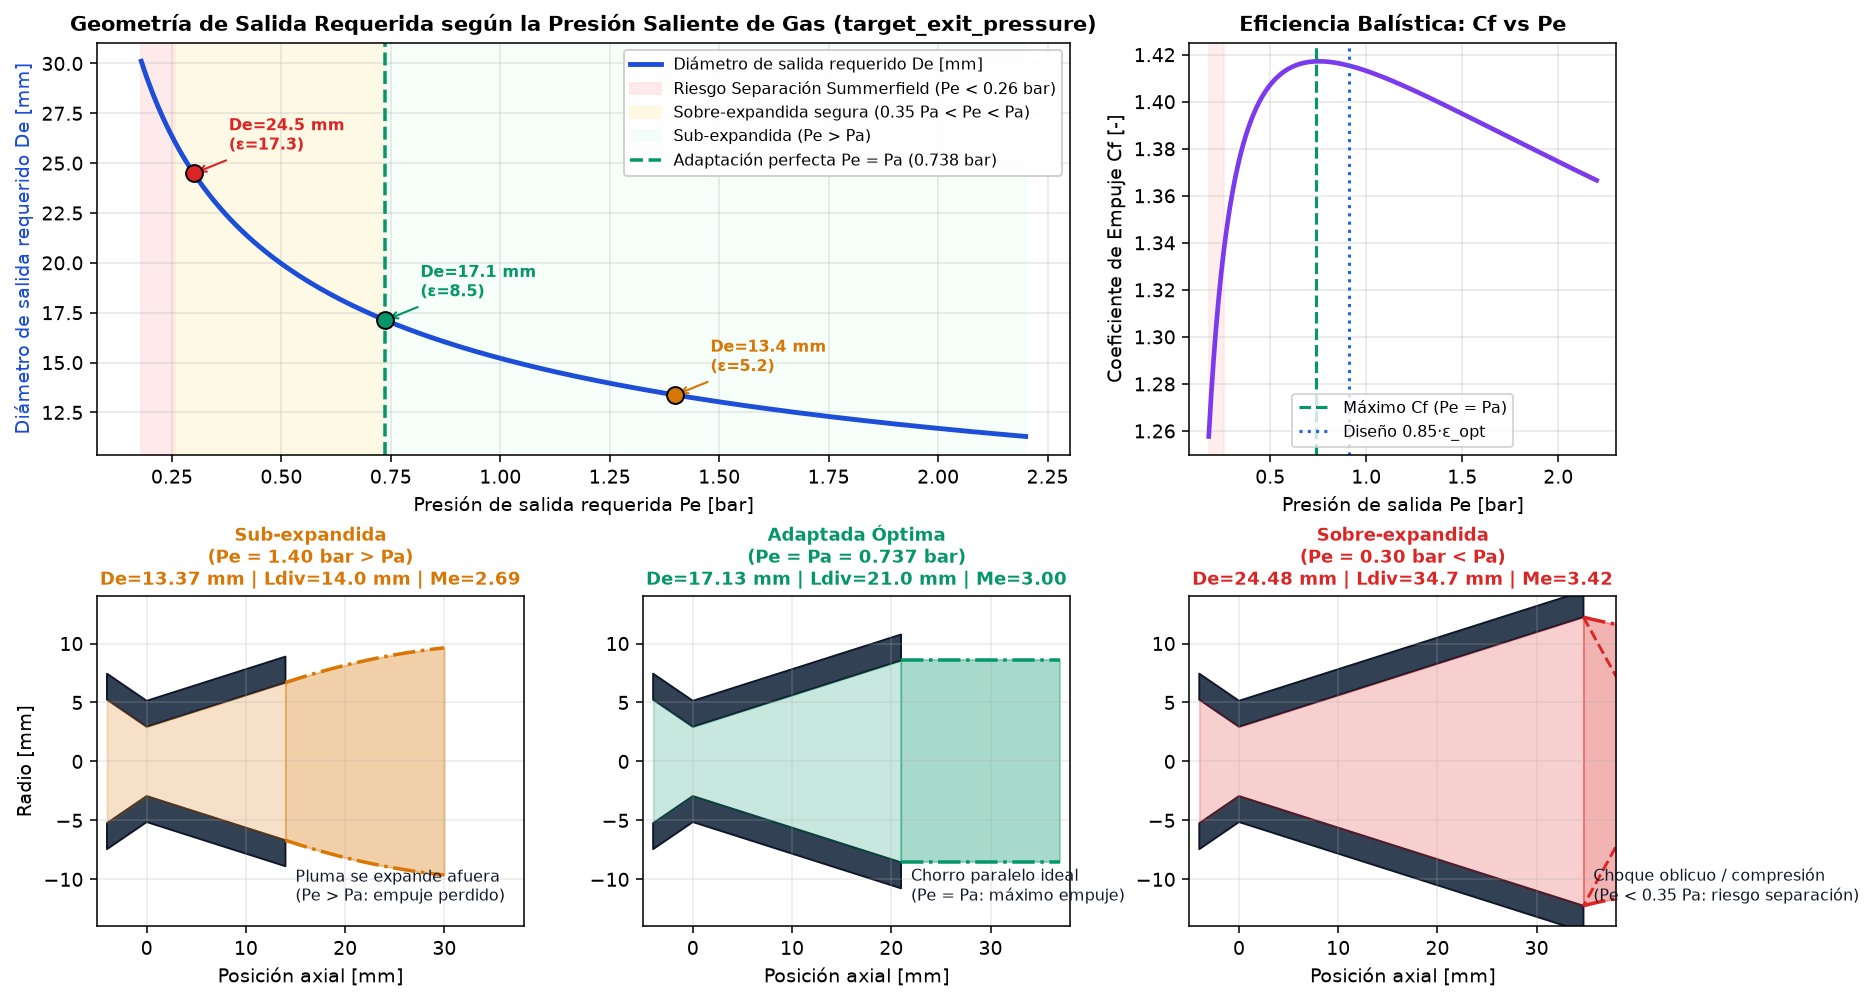

In [4]:
def plot_exit_pressure_parametric_study(save_path: Path | None = None):
    """Ilustra cómo dimension_nozzle ajusta la tobera según la presión de salida Pe requerida."""
    pc = 40.0e5
    dt = 5.88e-3
    pa = p_amb_bogota
    p_sep = 0.35 * pa  # Límite de separación de Summerfield

    # Barrido de presión de salida requerida Pe desde 0.18 bar hasta 2.20 bar
    pe_targets = np.linspace(0.18e5, 2.20e5, 160)
    de_mm_list = []
    eps_list = []
    cf_list = []

    for pe_req in pe_targets:
        nd = dimension_nozzle(
            throat_diameter=dt,
            chamber_pressure=pc,
            propellant=prop,
            chamber_diameter=42.0e-3,
            target_exit_pressure=float(pe_req),
            ambient_pressure=pa,
            efficiency=0.90,
        )
        de_mm_list.append(nd.exit_diameter * 1e3)
        eps_list.append(nd.area_ratio)
        cf_list.append(nd.thrust_coefficient)

    pe_bar = pe_targets / 1e5
    pa_bar = pa / 1e5
    p_sep_bar = p_sep / 1e5

    # Tres casos representativos llamando a dimension_nozzle(target_exit_pressure=...)
    cases = [
        ("Sub-expandida\n(Pe = 1.40 bar > Pa)", 1.40e5, "#d97706"),
        ("Adaptada Óptima\n(Pe = Pa = 0.737 bar)", pa, "#059669"),
        ("Sobre-expandida\n(Pe = 0.30 bar < Pa)", 0.30e5, "#dc2626"),
    ]

    fig = plt.figure(figsize=(14, 8.2), dpi=140)
    gs = fig.add_gridspec(2, 3, height_ratios=[1.25, 1.0], hspace=0.38, wspace=0.28)

    # Panel Superior Izquierdo: Diámetro de salida De y Razón de Áreas vs Pe requerida
    ax1 = fig.add_subplot(gs[0, :2])
    ax1.plot(
        pe_bar,
        de_mm_list,
        color="#1d4ed8",
        lw=2.5,
        label="Diámetro de salida requerido De [mm]",
    )
    ax1.axvspan(
        pe_bar[0],
        p_sep_bar,
        color="#fee2e2",
        alpha=0.7,
        label=f"Riesgo Separación Summerfield (Pe < {p_sep_bar:.2f} bar)",
    )
    ax1.axvspan(
        p_sep_bar,
        pa_bar,
        color="#fef3c7",
        alpha=0.45,
        label="Sobre-expandida segura (0.35 Pa < Pe < Pa)",
    )
    ax1.axvspan(
        pa_bar, pe_bar[-1], color="#ecfdf5", alpha=0.45, label="Sub-expandida (Pe > Pa)"
    )
    ax1.axvline(
        pa_bar,
        color="#059669",
        ls="--",
        lw=1.8,
        label=f"Adaptación perfecta Pe = Pa ({pa_bar:.3f} bar)",
    )

    for _label_c, pe_val, col in cases:
        nd_c = dimension_nozzle(
            dt, pc, prop, 42.0e-3, target_exit_pressure=pe_val, ambient_pressure=pa
        )
        ax1.scatter(
            [pe_val / 1e5],
            [nd_c.exit_diameter * 1e3],
            color=col,
            s=75,
            zorder=5,
            edgecolor="black",
        )
        ax1.annotate(
            f"De={nd_c.exit_diameter * 1e3:.1f} mm\n(ε={nd_c.area_ratio:.1f})",
            xy=(pe_val / 1e5, nd_c.exit_diameter * 1e3),
            xytext=(pe_val / 1e5 + 0.08, nd_c.exit_diameter * 1e3 + 1.2),
            fontsize=8.3,
            fontweight="bold",
            color=col,
            arrowprops={"arrowstyle": "->", "color": col, "lw": 1.1},
        )

    ax1.set_title(
        "Geometría de Salida Requerida según la Presión Saliente de Gas (target_exit_pressure)",
        fontsize=11,
        fontweight="bold",
    )
    ax1.set_xlabel("Presión de salida requerida Pe [bar]")
    ax1.set_ylabel("Diámetro de salida requerido De [mm]", color="#1d4ed8")
    ax1.grid(True, alpha=0.3)
    ax1.legend(loc="upper right", fontsize=8.0, framealpha=0.92)

    # Panel Superior Derecho: Coeficiente de Empuje Cf vs Pe requerida
    ax2 = fig.add_subplot(gs[0, 2])
    ax2.plot(pe_bar, cf_list, color="#7c3aed", lw=2.4)
    ax2.axvline(pa_bar, color="#059669", ls="--", lw=1.6, label="Máximo Cf (Pe = Pa)")
    ax2.axvline(
        nozzle_dims.exit_pressure / 1e5,
        color="#2563eb",
        ls=":",
        lw=1.6,
        label="Diseño 0.85·ε_opt",
    )
    ax2.axvspan(pe_bar[0], p_sep_bar, color="#fee2e2", alpha=0.6)
    ax2.set_title("Eficiencia Balística: Cf vs Pe", fontsize=11, fontweight="bold")
    ax2.set_xlabel("Presión de salida Pe [bar]")
    ax2.set_ylabel("Coeficiente de Empuje Cf [-]")
    ax2.grid(True, alpha=0.3)
    ax2.legend(loc="lower center", fontsize=8.2)

    # 3 Paneles Inferiores: Silueta a escala de la tobera y pluma de escape para los 3 casos
    for idx, (title_c, pe_val, col) in enumerate(cases):
        ax_c = fig.add_subplot(gs[1, idx])
        nd_c = dimension_nozzle(
            dt, pc, prop, 42.0e-3, target_exit_pressure=pe_val, ambient_pressure=pa
        )
        rt = nd_c.throat_diameter * 1e3 / 2.0
        re = nd_c.exit_diameter * 1e3 / 2.0
        ldiv = nd_c.divergent_length * 1e3

        # Pared divergente de la tobera
        x_noz = np.array([-4.0, 0.0, ldiv])
        r_noz = np.array([rt + 2.3, rt, re])
        ax_c.fill_between(
            x_noz, r_noz, r_noz + 2.2, color="#334155", edgecolor="#0f172a", hatch="///"
        )
        ax_c.fill_between(
            x_noz,
            -r_noz - 2.2,
            -r_noz,
            color="#334155",
            edgecolor="#0f172a",
            hatch="///",
        )
        ax_c.fill_between(x_noz, -r_noz, r_noz, color=col, alpha=0.22)

        # Pluma supersónica aguas abajo de la salida (x > ldiv)
        x_plume = np.linspace(ldiv, ldiv + 16.0, 60)
        dx_p = x_plume - ldiv
        if pe_val > pa * 1.05:
            # Sub-expandida: la pluma se abre hacia afuera (Pe > Pa)
            r_plume = re + 0.28 * dx_p - 0.006 * dx_p**2
            plume_note = "Pluma se expande afuera\n(Pe > Pa: empuje perdido)"
        elif abs(pe_val - pa) <= 0.05 * pa:
            # Adaptada: chorro supersónico paralelo
            r_plume = np.full_like(x_plume, re)
            plume_note = "Chorro paralelo ideal\n(Pe = Pa: máximo empuje)"
        else:
            # Sobre-expandida: la atmósfera comprime el chorro + diamantes de choque
            r_plume = re - 0.22 * dx_p + 0.011 * dx_p**2
            plume_note = (
                "Choque oblicuo / compresión\n(Pe < 0.35 Pa: riesgo separación)"
            )
            ax_c.plot(
                [ldiv, ldiv + 8.0, ldiv],
                [re, 0.0, -re],
                color="#dc2626",
                ls="--",
                lw=1.5,
            )

        ax_c.fill_between(x_plume, -r_plume, r_plume, color=col, alpha=0.35)
        ax_c.plot(x_plume, r_plume, color=col, lw=1.8, ls="-.")
        ax_c.plot(x_plume, -r_plume, color=col, lw=1.8, ls="-.")
        ax_c.set_xlim(-5, 38)
        ax_c.set_ylim(-14, 14)
        ax_c.set_title(
            f"{title_c}\nDe={nd_c.exit_diameter * 1e3:.2f} mm | Ldiv={ldiv:.1f} mm | Me={nd_c.exit_mach:.2f}",
            fontsize=9.3,
            fontweight="bold",
            color=col,
        )
        ax_c.text(ldiv + 1.0, -11.8, plume_note, fontsize=8.0, color="#0f172a")
        ax_c.set_xlabel("Posición axial [mm]")
        if idx == 0:
            ax_c.set_ylabel("Radio [mm]")
        ax_c.grid(True, alpha=0.25)

    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


plot_exit_pressure_parametric_study(fig_dir / "03_nozzle_exit_pressure_regimes.png")

---
## 3. Geometrías de Grano 1D y 2D por Transformada de Distancia Euclidiana (EDT)

Además del grano cilíndrico hueco clásico **`BATES`** y del grano tipo cigarrillo **`EndBurner`**, `PropulPy` incorpora el motor geométrico 2D basado en la **Transformada de Distancia Euclidiana (`scipy.ndimage.distance_transform_edt`)** —la misma técnica matemática empleada por `openMotor`— para evaluar geometrías perforadas complejas como **`Finocyl`** y **`Star`**.

En la siguiente figura generada por código visualizamos el **mapa exacto de distancia de regresión $x(X,Y)$** y los contornos del frente de llama a medida que avanza el quemado, junto con sus curvas de área de quemado $A_b(x)$:

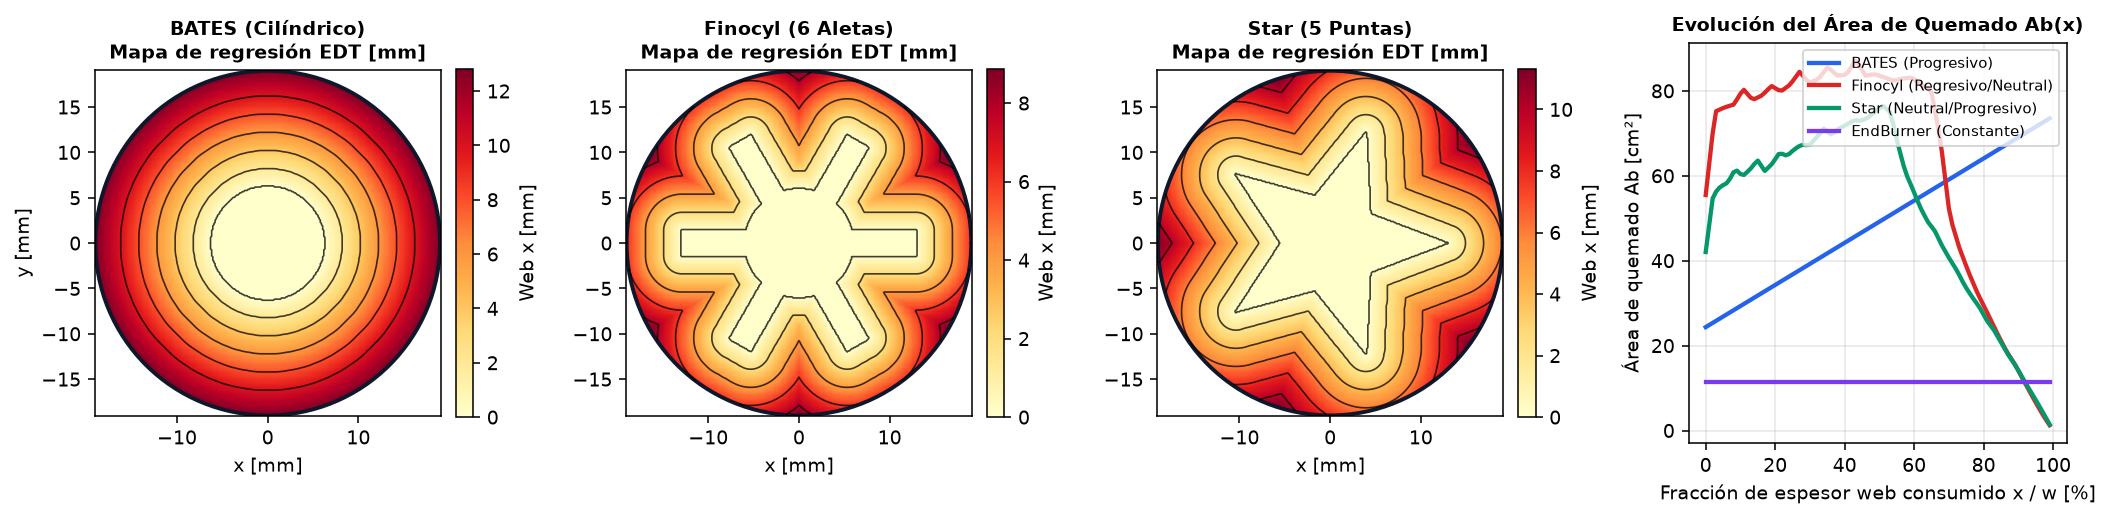

In [5]:
from scipy.ndimage import distance_transform_edt


def plot_grain_geometries_edt(save_path: Path | None = None):
    """Visualiza los mapas de regresión 2D (EDT) de BATES, Finocyl y Star y sus curvas Ab(x)."""
    d_out = 0.038
    length = 0.062

    g_bates = BATES(
        diameter=d_out, core_diameter=0.0125, length=length, inhibited_ends="both"
    )
    g_fino = Finocyl(
        diameter=d_out,
        core_diameter=0.012,
        fin_length=0.007,
        fin_width=0.0028,
        num_fins=6,
        length=length,
        inhibited_ends="both",
    )
    g_star = Star(
        diameter=d_out,
        inner_diameter=0.011,
        point_diameter=0.026,
        num_points=5,
        length=length,
        inhibited_ends="both",
    )
    g_end = EndBurner(diameter=d_out, length=0.015)

    fig, axs = plt.subplots(1, 4, figsize=(15, 3.8), dpi=140)
    r_out = d_out / 2.0
    lin = np.linspace(-r_out, r_out, 301)
    dx = lin[1] - lin[0]
    X, Y = np.meshgrid(lin, lin)
    R = np.hypot(X, Y)
    inside_casing = R <= r_out

    grain_2d_specs = [
        ("BATES (Cilíndrico)", R <= (0.0125 / 2.0)),
        ("Finocyl (6 Aletas)", g_fino._build_core_mask(X, Y)),
        ("Star (5 Puntas)", g_star._build_core_mask(X, Y)),
    ]

    for idx, (title, core_mask) in enumerate(grain_2d_specs):
        ax = axs[idx]
        dist_mm = distance_transform_edt(~(core_mask & inside_casing)) * dx * 1e3
        dist_mm[~inside_casing] = np.nan
        dist_mm[core_mask & inside_casing] = 0.0

        im = ax.pcolormesh(X * 1e3, Y * 1e3, dist_mm, cmap="YlOrRd", shading="auto")
        # Contornos del frente de llama cada 2 mm de regresión web
        ax.contour(
            X * 1e3,
            Y * 1e3,
            dist_mm,
            levels=[0.1, 2.0, 4.0, 6.0, 8.0, 10.0],
            colors="black",
            linewidths=0.85,
            alpha=0.75,
        )
        circle = plt.Circle((0, 0), r_out * 1e3, fill=False, ec="#0f172a", lw=2.0)
        ax.add_patch(circle)
        ax.set_aspect("equal")
        ax.set_title(
            f"{title}\nMapa de regresión EDT [mm]", fontsize=10, fontweight="bold"
        )
        ax.set_xlabel("x [mm]")
        if idx == 0:
            ax.set_ylabel("y [mm]")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Web x [mm]")

    # Panel 4: Comparativa de Área de Quemado Ab(x)
    ax_ab = axs[3]
    for label, g, col in [
        ("BATES (Progresivo)", g_bates, "#2563eb"),
        ("Finocyl (Regresivo/Neutral)", g_fino, "#dc2626"),
        ("Star (Neutral/Progresivo)", g_star, "#059669"),
        ("EndBurner (Constante)", g_end, "#7c3aed"),
    ]:
        xs = np.linspace(0.0, g.web_thickness * 0.99, 100)
        ab_cm2 = np.asarray(g.burn_area(xs)) * 1e4
        ax_ab.plot(xs / g.web_thickness * 100.0, ab_cm2, lw=2.2, color=col, label=label)

    ax_ab.set_title(
        "Evolución del Área de Quemado Ab(x)", fontsize=10, fontweight="bold"
    )
    ax_ab.set_xlabel("Fracción de espesor web consumido x / w [%]")
    ax_ab.set_ylabel("Área de quemado Ab [cm²]")
    ax_ab.grid(True, alpha=0.3)
    ax_ab.legend(fontsize=7.8, loc="upper right")

    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


plot_grain_geometries_edt(fig_dir / "04_grain_edt_geometries.png")

---
## 4. Ensamblaje del Motor `UltraLuminics`, Auditoría de Seguridad y Simulación Cuasi-Estacionaria

Ahora ensamblamos los **2 granos BATES** ($D = 38\text{ mm}$, $d_0 = 12.5\text{ mm}$, $L = 62\text{ mm}$), la carcasa de **Aluminio 6061-T6** ($\sigma_y = 276\text{ MPa}$) y la tobera dimensionada en un objeto `SolidMotor`.

Antes de disparar la simulación, ejecutamos `print_check_report(motor)` para auditar:
- **Relación Puerto-a-Garganta ($A_p / A_t \ge 2.0$)** para evitar quemado erosivo.
- **Factor de seguridad estructural de Barlow ($SF_y \ge 1.5$)** en la carcasa.
- **Ausencia de separación de flujo de Summerfield** en la tobera.

                  PROPULPY MOTOR DESIGN & SAFETY AUDIT
[OK]       Port-to-Throat Ratio (Ap/At)    : Port-to-throat ratio (4.52) is safe (>= 2.0).
[OK]       Initial Kn                      : Initial Kn (328.3) is within nominal operating range (200 - 350).
[WARNING]  Peak Kn                         : Peak Kn (381.1) is elevated (350 - 400); verify casing pressure rating.
[OK]       Grain Core Ratio (d/D)          : Grain core-to-diameter ratio d/D (0.33) is well proportioned (0.25 - 0.60).
[OK]       Grain Aspect Ratio (L/D)        : Grain segment aspect ratio L/D (1.63) promotes near-neutral burn (1.2 - 2.5).
[WARNING]  Peak Chamber Pressure (bar)     : Peak chamber pressure (49.1 bar) is high; ensure pressure vessel rating.
[OK]       Casing Safety Factor            : Casing safety factor (4.89) is generous (>= 2.0).
[OK]       Nozzle Separation (Pe/Pa)       : Nozzle exit pressure ratio Pe/Pa (0.80) is well above separation threshold.
             PROPULPY SOLID MOTOR SUMMARY (H165)

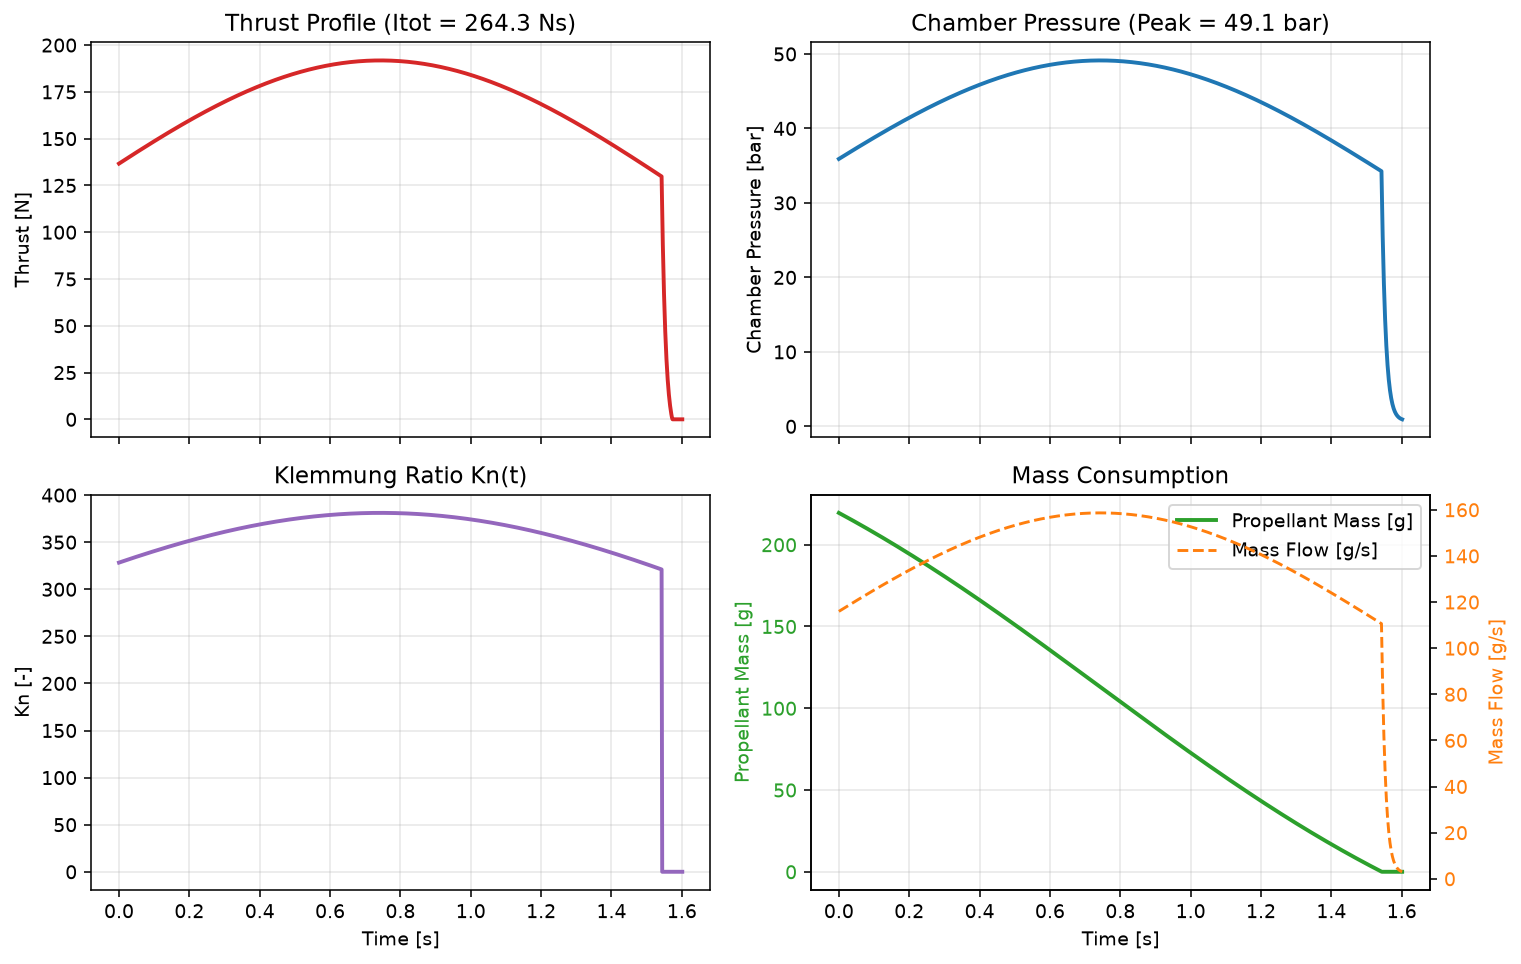

In [6]:
# 1. Definir los 2 segmentos de grano BATES y la cámara de combustión
grains = [
    BATES(
        diameter=38.0e-3,
        core_diameter=12.5e-3,
        length=62.0e-3,
        inhibited_ends="neither",
    )
] * 2

chamber = Chamber(
    inner_diameter=42.0e-3,
    length=0.19,
    outer_diameter=46.0e-3,
    yield_strength=276.0e6,  # Aluminio 6061-T6
)

# 2. Ensamblar el SolidMotor con la tobera diseñada por dimension_nozzle()
motor = SolidMotor(
    propellant=prop,
    grains=grains,
    nozzle=nozzle_dims.to_nozzle(),
    chamber=chamber,
)

# 3. Auditoría automática de seguridad y reglas de diseño
print_check_report(motor)

# 4. Simulación cuasi-estacionaria con descarga de cámara (blowdown)
results = motor.simulate(ambient_pressure=env)
results.info()

# 5. Gráfica diagnóstica de 4 paneles
fig_sim = results.plot(show=False)
fig_sim.savefig(
    fig_dir / "05_ultraluminics_firing_dashboard.png", dpi=150, bbox_inches="tight"
)
plt.show()

---
## 5. Exportación a `.csv`, `.eng`, `.ric` (`openMotor`) y Conversión a `RocketPy`

Finalmente, `MotorResults` permite exportar la curva de empuje a todos los formatos estándar de la comunidad aeroespacial:
- **`.csv`**: Tabla temporal completa (`Time, Thrust, ChamberPressure_Pa, MassFlow_kg_s, PropellantMass_kg`).
- **`.eng` (RASP)**: Compatible con `OpenRocket`, `RockSim` y `RocketPy`.
- **`.ric` (`openMotor`)**: Archivo de configuración bidireccional compatible con `openMotor` y recargable vía `SolidMotor.from_ric()`.
- **`results.to_rocketpy()`**: Construye en una sola línea el objeto `rocketpy.SolidMotor` asignando correctamente `nozzle_radius` (radio de salida) y `throat_radius` (radio de garganta).

In [7]:
out_dir = Path("outputs")
out_dir.mkdir(exist_ok=True)

csv_path = results.export_csv(out_dir / "ultraluminics_motor.csv")
eng_path = results.export_eng(out_dir / "ultraluminics_motor.eng", motor_name="H150-UL")
ric_path = results.export_ric(
    out_dir / "ultraluminics_motor.ric", description="UltraLuminics KNSB"
)

print(f"Archivos exportados exitosamente en '{out_dir.resolve()}':")
print(f"  * CSV : {csv_path.name}")
print(f"  * ENG : {eng_path.name}")
print(f"  * RIC : {ric_path.name}")

# Verificar importación inversa desde formato openMotor (.ric)
reloaded_motor = SolidMotor.from_ric(ric_path)
print(
    f"\nMotor recargado desde .ric: {reloaded_motor.number_of_grains} granos, Kn inicial = {reloaded_motor.initial_kn:.1f}"
)

# Convertir en una línea a un objeto rocketpy.SolidMotor listo para volar
rp_motor = results.to_rocketpy(
    dry_mass=0.600,
    dry_inertia=(0.05, 0.05, 0.001),
    center_of_dry_mass_position=0.10,
)
print(
    f"Objeto rocketpy.SolidMotor generado -> Impulso Total = {rp_motor.total_impulse:.1f} N·s"
)

Archivos exportados exitosamente en 'C:\Users\ander\OneDrive\Desktop\UltraLuminics\PropulPy\outputs':
  * CSV : ultraluminics_motor.csv
  * ENG : ultraluminics_motor.eng
  * RIC : ultraluminics_motor.ric

Motor recargado desde .ric: 2 granos, Kn inicial = 328.3
Objeto rocketpy.SolidMotor generado -> Impulso Total = 264.3 N·s
